In [1]:
import  numpy   as np
import  pandas  as pd
import  seaborn as sns
import  matplotlib.pyplot as plt
from    sklearn.model_selection    import train_test_split, cross_val_score, RandomizedSearchCV
from    sklearn.impute             import SimpleImputer
from    sklearn.preprocessing      import StandardScaler, OneHotEncoder, PowerTransformer
from    sklearn.pipeline           import Pipeline
from    sklearn.compose            import ColumnTransformer
from    sklearn.linear_model       import LogisticRegression
from    sklearn.tree               import DecisionTreeClassifier
from    sklearn.ensemble           import RandomForestClassifier, GradientBoostingClassifier
from    sklearn.metrics            import accuracy_score, f1_score, confusion_matrix
import  joblib

In [2]:
df = pd.read_csv("../data/AB_NYC_2019.csv")

In [3]:
df.head(5)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [5]:
df.shape

(48895, 16)

In [6]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


EDA

In [7]:
print(df.isnull().sum())
print(df.isnull().sum().sum())


id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64
20141


In [8]:
df.duplicated().sum()

np.int64(0)

room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64


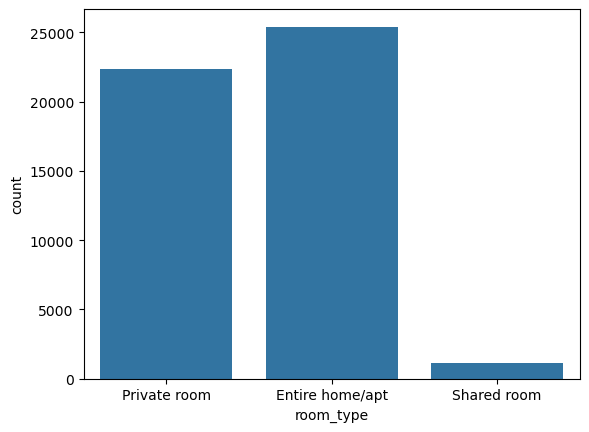

In [9]:
print(df['room_type'].value_counts())
sns.countplot(x="room_type", data=df)
plt.show()

classes are imbalance

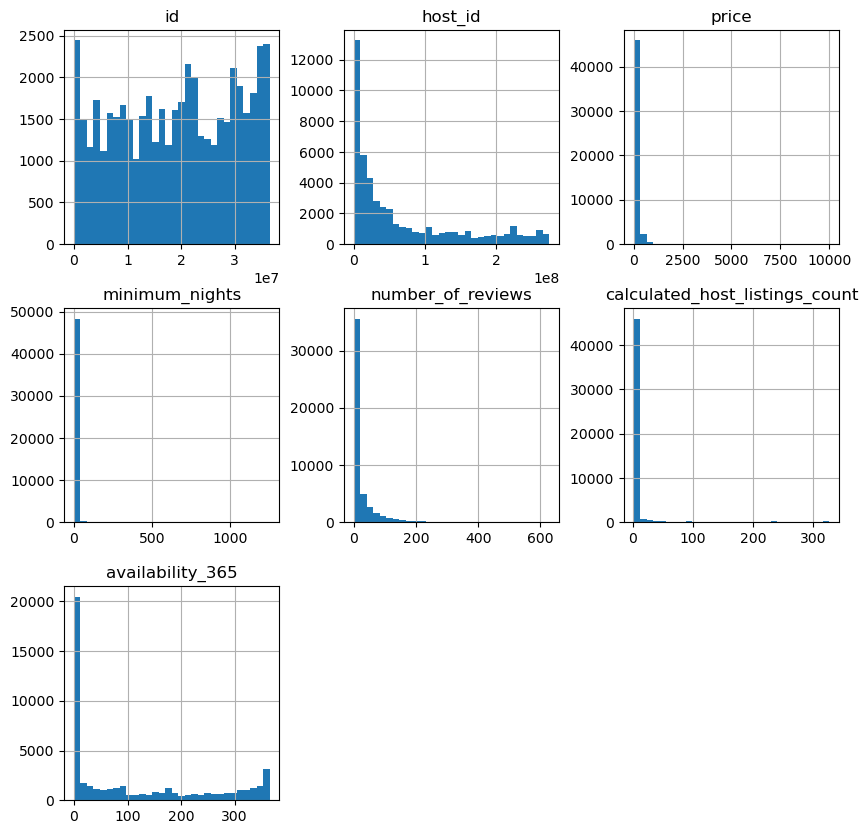

In [10]:
df.select_dtypes(include="int").hist(bins=30, figsize=(10, 10))
plt.show()


<Axes: xlabel='room_type', ylabel='price'>

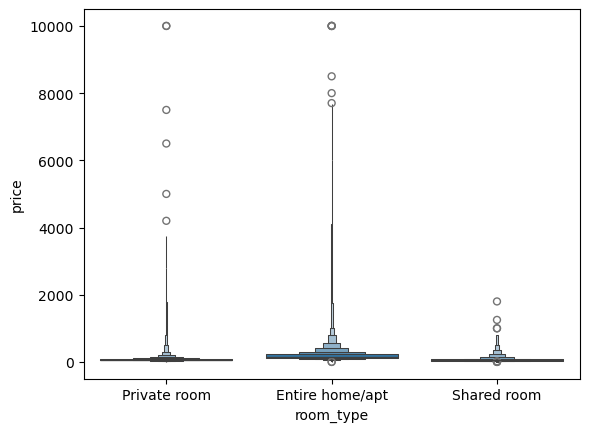

In [11]:
sns.boxenplot(x="room_type", y="price", data=df)


<Axes: >

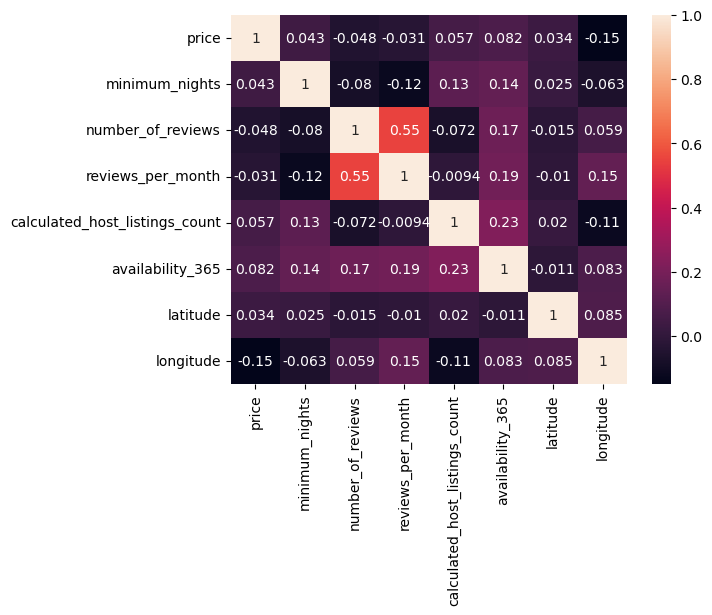

In [12]:
numeric_col = ['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365']
sns.heatmap(df[numeric_col + ['latitude', 'longitude']].corr(), annot=True)

<Axes: xlabel='longitude', ylabel='latitude'>

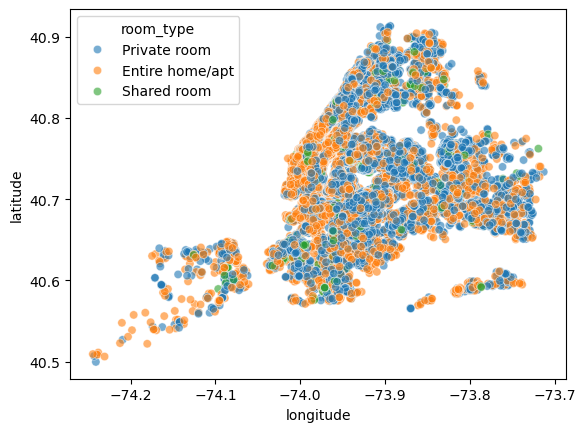

In [13]:
sns.scatterplot(x="longitude", y="latitude", data=df, hue="room_type", alpha=0.6)

Cleaning, and Feature engineering

In [14]:
# 
df_clean = df.drop(columns=['id', 'name', 'host_id', 'host_name', 'last_review'])

# 
df_clean['reviews_per_month'] = df['reviews_per_month'].fillna(0)


In [15]:
df_clean.columns

Index(['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [16]:
price_cap  = df['price'].quantile(0.99)
nights_cap = df['minimum_nights'].quantile(0.99)

df['price']          = df['price'].clip(upper=price_cap)
df['minimum_nights'] = df['minimum_nights'].clip(upper=nights_cap)


In [17]:
X = df_clean.drop(columns=['room_type'])
y = df_clean['room_type']

In [18]:
df_clean.shape

(48895, 11)

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42, stratify=y)


In [20]:
numeric_col = ['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'] + ['latitude', 'longitude']

categorical_cols = ["neighbourhood_group", "neighbourhood"]

In [21]:

# for numerical
numeric_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    # ('skewness', PowerTransformer(method='yeo-johnson')),
    ('scale',  StandardScaler())
])

# for ctegorical
categorical_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

In [22]:
preprocessor = ColumnTransformer(transformers=[
    ('numerical',   numeric_pipeline,     numeric_col),
    ('categorical', categorical_pipeline, categorical_cols)
])
preprocessor

,transformers,"[('numerical', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [23]:
models = {
    "Logistic Regression":    LogisticRegression(class_weight='balanced', random_state=42),
    "Decision Tree"      :    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "Random Forest"      :    RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting"  :    GradientBoostingClassifier(random_state=42)
}

In [24]:
for name, model in models.items():
    pipe = Pipeline(steps=[("preprocess", preprocessor), ("classifier", model)])
    acc_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)
    f1_macro   = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1_macro", n_jobs=-1)

    print(f"{name}: Accuracy: {acc_scores.mean():.4f}, F1 Macro: {f1_macro.mean():.4f}")

Logistic Regression: Accuracy: 0.6349, F1 Macro: 0.5060
Decision Tree: Accuracy: 0.7840, F1 Macro: 0.6671
Random Forest: Accuracy: 0.8530, F1 Macro: 0.7212
Gradient Boosting: Accuracy: 0.8509, F1 Macro: 0.7074


In [25]:
best_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor), 
    ("random forest", RandomForestClassifier(class_weight='balanced', random_state=42))])


In [26]:
param_distributions = {
    "random forest__n_estimators": [100, 200, 300],
    "random forest__max_depth": [None, 10, 20, 30],
    "random forest__min_samples_split": [2, 5, 10],
    "random forest__min_samples_leaf": [1, 2, 4]
}

random_search = RandomizedSearchCV(estimator=best_pipeline, param_distributions=param_distributions, n_iter=15, cv=5, n_jobs=-1, random_state=42, scoring="f1_macro")

random_search.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'random forest__max_depth': [None, 10, ...], 'random forest__min_samples_leaf': [1, 2, ...], 'random forest__min_samples_split': [2, 5, ...], 'random forest__n_estimators': [100, 200, ...]}"
,n_iter,15
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [27]:
best_pipeline = random_search.best_estimator_

In [28]:
y_pred = best_pipeline.predict(X_test)


acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")

print(f"Test Accuracy: {acc:.4f}")
print(f"Test F1 Macro: {f1:.4f}")

Test Accuracy: 0.8519
Test F1 Macro: 0.7422


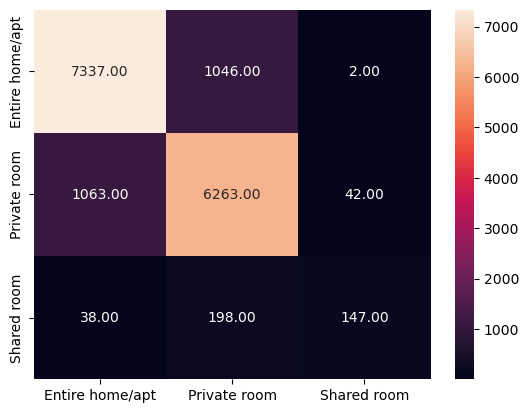

In [29]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, xticklabels=best_pipeline.classes_, yticklabels=best_pipeline.classes_, fmt=".2F")
plt.show()

In [30]:
joblib.dump(best_pipeline, "../model/Model_Pipeline.pkl", compress=3)

['../model/Model_Pipeline.pkl']